# Мера сходства и поиск похожих объектов

**Фундаментальная математика для алгоритмизации и программирования**

Задача лекции — научиться переводить содержательный вопрос о данных в математическую модель и алгоритм. В каталоге фильмов слово «похожий» само по себе не задаёт способ поиска. Мы уточним его смысл: будем искать фильмы, у которых жанровое описание близко к описанию выбранного фильма — **Toy Story**.

Вход алгоритма — готовый каталог и фильм-запрос. Выход — упорядоченный список других фильмов, которые удовлетворяют заданным условиям сходства. Для этого понадобятся идеи из теории: множество присутствующих признаков, пересечение и объединение, коэффициент Жаккара, логическое И и вложенность множеств при изменении порога. Python реализует каждую из этих идей отдельным шагом.

Сначала проверим модель на паре **Toy Story / Jumanji**, затем применим её ко всему MovieLens. В самостоятельной части перенесём тот же алгоритм на **UCI Zoo**. Так мы проверим, какие части решения зависят от данных, а какие задаются математикой.

## 1. Разобранный пример:

Нужно установить, насколько совпадают жанровые описания **Toy Story** и **Jumanji**. Мы сначала увидим исходные признаки, затем вычислим сходство. Такая небольшая пара позволяет проверить не только число, но и причину его появления.

Математическая задача этой части — получить множества $A$ и $B$ из реальных записей и проверить формулу $J(A,B)=|A\cap B|/|A\cup B|$. Результат одной пары станет образцом для поиска по всему каталогу.

### 1.1. Импорт библиотек

Чтобы применить математическую модель к реальным объектам, нужно прочитать их описания из датасета и увидеть результаты расчётов. Библиотеки обеспечат загрузку и показ данных; правило сходства мы запишем явно, по формуле из лекции.

pandas читает CSV и показывает таблицы, matplotlib строит графики. Пересечение, объединение, отбор и подсчёт выполняются обычными операциями Python.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Далее мы будем отделять сведения об объекте от признаков, по которым сравниваем объекты. Такое разделение позволяет понимать, на основании каких данных алгоритм называет фильмы похожими. Файлы movies.csv и zoo.csv должны быть доступны рядом с блокнотом или загружены в Colab.

### 1.2. Загрузка каталога

В задаче поиска сначала нужно определить объект сравнения и его описание. В MovieLens объект — фильм, а доступное нам описание — набор жанров. Название помогает прочитать выдачу; идентификатор позволяет однозначно указать запрос и исключить его из результата.

После чтения CSV переводим строки в список словарей: один словарь описывает один фильм. Например, movie["title"] хранит название, movie["genres"] — строку жанров.

In [2]:
movies_table = pd.read_csv("movies.csv")
display(movies_table.head())
movies = movies_table.to_dict("records")
print("Число фильмов:", len(movies))

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Число фильмов: 9742


Каталог содержит 9742 фильма. Мы сравниваем их по жанрам; пользовательские оценки в эту модель не входят. Поэтому результат будет отвечать на вопрос о близости жанровых описаний. Идентификатор movieId отличает запись от её позиции в списке.

### 1.3. Проверка описаний

Коэффициент Жаккара сравнивает известные наборы признаков. Если жанры не указаны, мы не можем установить, какие из них совпадают с запросом. Значение (no genres listed) обозначает отсутствие информации; включение этой строки как названия жанра исказило бы математическую модель.

В этом упражнении неизвестные описания исключаем. Цикл и условие формируют каталог записей, для которых выбранное сравнение имеет содержательный смысл.

In [3]:
catalog = []
unknown_count = 0

for movie in movies:
    if movie["genres"] == "(no genres listed)":
        unknown_count = unknown_count + 1
    else:
        catalog.append(movie)

print("Без указанного описания:", unknown_count)
print("Записей для сравнения:", len(catalog))

Без указанного описания: 34
Записей для сравнения: 9708


Исключены 34 записи, осталось 9708. Поиск теперь относится только к фильмам с известными жанрами: об исключённых фильмах он не даёт вывода. Исходная таблица movies_table сохранена, поэтому границу анализируемой части датасета можно проверить.

### 1.4. Две исходные записи

До расчёта всего каталога проверим модель на двух объектах с легко обозримыми описаниями. Toy Story станет запросом, Jumanji — первым кандидатом. Так мы сможем сопоставить вычисленное число с реальными жанрами, а затем использовать эту пару для проверки алгоритма.

Ищем записи по movieId и сохраняем их описания в отдельных переменных.

In [4]:
for movie in catalog:
    if movie["movieId"] == 1:
        toy_story = movie
    if movie["movieId"] == 2:
        jumanji = movie

print(toy_story["title"], toy_story["genres"])
print(jumanji["title"], jumanji["genres"])

Toy Story (1995) Adventure|Animation|Children|Comedy|Fantasy
Jumanji (1995) Adventure|Children|Fantasy


У Toy Story пять жанров, у Jumanji три, причём все три входят в описание Toy Story. Значит, у фильмов есть общие признаки, но описания не совпадают полностью. Мера сходства должна сохранить это различие: ожидать значение 1 здесь нельзя.

### 1.5. Преобразование строк в множества

На лекции сходство определено для множеств. Поэтому каждую строку жанров нужно представить множеством присутствующих признаков. Для нашей задачи порядок жанров и повтор одного названия не должны влиять на оценку: один жанр учитывается один раз.

split("|") выделяет названия, set создаёт множество. Поле genre_set сохраняет математическое описание каждого фильма; A и B — множества выбранной пары.

In [5]:
for movie in catalog:
    genres = movie["genres"].split("|")
    movie["genre_set"] = set(genres)

query_id = 1
A = toy_story["genre_set"]
B = jumanji["genre_set"]
print("Toy Story:", sorted(A))
print("Jumanji:", sorted(B))

Toy Story: ['Adventure', 'Animation', 'Children', 'Comedy', 'Fantasy']
Jumanji: ['Adventure', 'Children', 'Fantasy']


Получены A = {Adventure, Animation, Children, Comedy, Fantasy} и B = {Adventure, Children, Fantasy}. Теперь B является подмножеством A. Это конкретный случай связи между отношением включения и мерой сходства, который можно проверить по исходным данным.

### 1.6. Пересечение и объединение

Слово «совпадают» теперь получает точный смысл: общие жанры образуют пересечение A и B. Для оценки доли совпадений также нужен общий объём двух описаний — все различные жанры, входящие хотя бы в одно из них, то есть объединение.

Операторы & и | реализуют эти две операции над множествами. len считает элементы полученных наборов.

In [6]:
intersection = A & B
union = A | B
print("Пересечение:", sorted(intersection))
print("Объединение:", sorted(union))
print("Размеры:", len(A), len(B), len(intersection), len(union))

Пересечение: ['Adventure', 'Children', 'Fantasy']
Объединение: ['Adventure', 'Animation', 'Children', 'Comedy', 'Fantasy']
Размеры: 5 3 3 5


Пересечение содержит 3 жанра, объединение — 5. При сложении 5 + 3 общие жанры были бы учтены дважды; вычитание 3 устраняет повторный счёт. Поэтому формула включений и исключений даёт тот же знаменатель: 5 + 3 − 3 = 5.

### 1.7. Вычисление Жаккара

Три совпадения сами по себе ещё не показывают, какая часть описаний общая. Жаккар нормирует их количество на размер объединения. Так разные пары можно сравнивать по одной шкале от 0 до 1, даже если число признаков у объектов различается.

Числитель, знаменатель и отношение вычисляем отдельными строками. Дополнительно проверяем знаменатель формулой включений и исключений.

In [7]:
common_count = len(intersection)
union_count = len(union)
j_pair = common_count / union_count
union_by_formula = len(A) + len(B) - common_count

print("Общих жанров:", common_count)
print("Размер объединения:", union_count)
print("Объединение по формуле:", union_by_formula)
print("Жаккар:", j_pair)

Общих жанров: 3
Размер объединения: 5
Объединение по формуле: 5
Жаккар: 0.6


J(A,B) = 3/5 = 0,6. Это доля общих жанров среди всех различных жанров пары. Хотя B входит в A, сходство меньше 1: у Toy Story остаются два жанра, которых нет у Jumanji. Оценка описывает выбранные признаки и не является вероятностью того, что фильм понравится зрителю.

### 1.8. Проверка через бинарные списки

Признаки можно хранить множеством или списком нулей и единиц. Единица означает наличие жанра, ноль — отсутствие. Чтобы сравнение имело смысл, порядок жанров должен быть одинаковым у обоих фильмов.

Сначала получим общий список жанров `features`. Для каждого жанра проверим его наличие в Toy Story и Jumanji и запишем 1 или 0 в списки `query` и `candidate`.

Затем `zip` возьмёт значения двух списков попарно. Если оба значения равны 1, жанр общий: увеличиваем счётчик. Это простая реализация размера пересечения. Для бинарных значений она даёт тот же результат, что и сумма попарных произведений из лекции.

In [8]:
features = sorted(A | B)
query = []
candidate = []

for genre in features:
    if genre in A:
        query.append(1)
    else:
        query.append(0)

    if genre in B:
        candidate.append(1)
    else:
        candidate.append(0)

common = 0
for x, y in zip(query, candidate):
    if x == 1 and y == 1:
        common = common + 1

union_size = sum(query) + sum(candidate) - common

print("Жанры:", features)
print("Toy Story:", query)
print("Jumanji:", candidate)
print("Общих:", common, "объединение:", union_size)

if union_size > 0:
    score = common / union_size
    print("Жаккар:", score)

Жанры: ['Adventure', 'Animation', 'Children', 'Comedy', 'Fantasy']
Toy Story: [1, 1, 1, 1, 1]
Jumanji: [1, 0, 1, 0, 1]
Общих: 3 объединение: 5
Жаккар: 0.6


Условие совместного наличия выполняется три раза: общих жанров три. Суммы единиц в списках равны пяти и трём — это размеры исходных множеств. Общие жанры при сложении учтены дважды, поэтому вычитаем `common`: 5 + 3 − 3 = 5. Сходство снова равно 3/5 = 0,6. Две формы хранения признаков реализуют одну математическую модель.

## 2. Поиск по каталогу MovieLens

Сравнение одной пары проверено. Теперь задача — найти **другие фильмы с близким жанровым описанием к Toy Story**. Запрос остаётся фиксированным, а кандидатом последовательно становится каждый фильм каталога.

В этой части соединим три разных решения: вычисление сходства отвечает за оценку, логические условия — за допуск, сортировка — за порядок выдачи. Затем исследуем, как изменение порога влияет на множество кандидатов. Каждый шаг использует результаты предыдущих.

### 2.1. Число признаков в описаниях

Если у фильмов разное число жанров, одинаковое количество совпадений может составлять разную долю двух описаний. Проверим, различаются ли размеры множеств в нашем датасете.

В список `genre_sizes` запишем число жанров каждого фильма. `set` оставит различные размеры, а `sorted` расположит их по возрастанию. Метод `count` считает, сколько раз размер встречается в списке: столько фильмов имеют это число жанров. Эти частоты покажем на графике.

1 жанров: 2817 фильмов
2 жанров: 3218 фильмов
3 жанров: 2338 фильмов
4 жанров: 987 фильмов
5 жанров: 271 фильмов
6 жанров: 63 фильмов
7 жанров: 12 фильмов
8 жанров: 1 фильмов
10 жанров: 1 фильмов


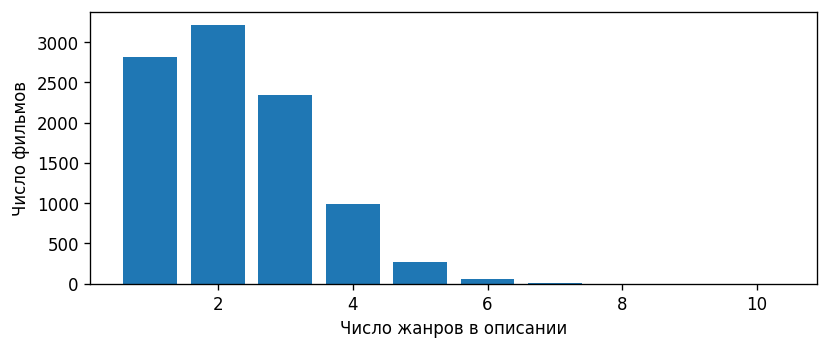

In [9]:
genre_sizes = []
for movie in catalog:
    size = len(movie["genre_set"])
    genre_sizes.append(size)

sizes = sorted(set(genre_sizes))
frequencies = []

for size in sizes:
    count = genre_sizes.count(size)
    frequencies.append(count)
    print(size, "жанров:", count, "фильмов")

plt.figure(figsize=(7, 3))
plt.bar(sizes, frequencies)
plt.xlabel("Число жанров в описании")
plt.ylabel("Число фильмов")
plt.show()

В каталоге есть описания разной длины. Значит, простой подсчёт общих жанров не учитывает существенное свойство данных. Далее сравним кандидатов с одинаковым числом совпадений и проверим, как размер объединения меняет коэффициент Жаккара.

### 2.2. Одна функция сравнения

Проверенную формулу нужно сделать правилом, одинаковым для любого кандидата. Функция compare_sets получает только два множества: ей не нужны название фильма или структура CSV. Такое отделение формулы от источника данных позволит позже применить её к животным.

Функция возвращает размер пересечения, размер объединения и их отношение. Проверка нулевого знаменателя явно задаёт границу применимости дроби.

In [10]:
def compare_sets(left, right):
    common = len(left & right)
    union_size = len(left | right)

    if union_size == 0:
        return common, union_size, None

    return common, union_size, common / union_size

print("Проверка пары:", compare_sets(A, B))
print("Пустые наборы:", compare_sets(set(), set()))

Проверка пары: (3, 5, 0.6)
Пустые наборы: (0, 0, None)


Для разобранной пары функция возвращает (3, 5, 0.6). Для двух пустых множеств отношение 0/0 не определено, поэтому результатом оценки служит None. В наших сравнениях запрос непустой, объединение содержит его признаки и всегда имеет положительный размер.

### 2.3. Вычисление для всех записей

Поиск по каталогу — это повторение одного математического сравнения. Множество запроса A фиксировано, а множество кандидата меняется от записи к записи. Для каждого фильма нужно сохранить не только оценку, но и её числитель со знаменателем, чтобы результат оставался объяснимым.

Цикл вызывает compare_sets для всех записей и сохраняет ответы в result вместе с идентификатором и названием фильма.

In [11]:
result = []
for movie in catalog:
    common, union_size, score = compare_sets(A, movie["genre_set"])
    row = {
        "movieId": movie["movieId"],
        "title": movie["title"],
        "common": common,
        "union": union_size,
        "jaccard": score
    }
    result.append(row)

display(pd.DataFrame(result[:5]))

,movieId,title,common,union,jaccard
0,1,Toy Story (1995),5,5,1.000000
1,2,Jumanji (1995),3,5,0.600000
2,3,Grumpier Old Men (1995),1,6,0.166667
3,4,Waiting to Exhale (1995),1,7,0.142857
4,5,Father of the Bride Part II (1995),1,5,0.200000


Получены 9708 сравнений относительно одного запроса. Теперь каждый кандидат имеет числовое описание отношения к Toy Story. Пока это все оценки, а не готовая выдача: условия допуска и порядок результатов будут заданы отдельно.

### 2.4. Проверка по известным записям

Корректность реализации проверяется через свойства математического правила. Для непустого множества сходство с собой равно 1; для непересекающихся множеств — 0. Разобранная вручную пара должна сохранить значение 0,6 после включения в общий цикл.

Проверяем Toy Story, Jumanji и Heat. Эти три случая связывают исходные записи, формулу и массовый расчёт.

In [12]:
for row in result:
    if row["movieId"] in [1, 2, 6]:
        print(row["title"], "Жаккар:", row["jaccard"])

Toy Story (1995) Жаккар: 1.0
Jumanji (1995) Жаккар: 0.6
Heat (1995) Жаккар: 0.0


Получены ожидаемые 1, 0,6 и 0. Эти проверки подтверждают понятные случаи модели и помогают обнаружить ошибку в составе признаков или привязке результатов к фильмам. Они не заменяют все возможные проверки, но дают основание интерпретировать последующий отбор.

### 2.5. Совпадения и нормированное сходство

Выберем фильмы, у которых с Toy Story ровно три общих жанра. Числитель одинаков, поэтому различия в сходстве объясняются знаменателем — размером объединения.

Запишем размеры объединений таких пар в список `union_sizes`. Затем для каждого различного размера посчитаем число фильмов методом `count` и выведем сходство `3 / union_size`. Так увидим, почему одно число совпадений даёт разные оценки.

In [13]:
union_sizes = []
for row in result:
    if row["common"] == 3:
        union_sizes.append(row["union"])

for union_size in sorted(set(union_sizes)):
    count = union_sizes.count(union_size)
    score = 3 / union_size
    print("Объединение:", union_size,
          "фильмов:", count,
          "Жаккар:", score)

Объединение: 5 фильмов: 155 Жаккар: 0.6
Объединение: 6 фильмов: 123 Жаккар: 0.5
Объединение: 7 фильмов: 53 Жаккар: 0.42857142857142855
Объединение: 8 фильмов: 10 Жаккар: 0.375
Объединение: 9 фильмов: 1 Жаккар: 0.3333333333333333


При объединении из пяти жанров сходство равно 0,6, из шести — 0,5, из девяти — приблизительно 0,333. Три совпадения во всех случаях одинаковы, но их доля различна. Поэтому ранжирование по Жаккару выражает близость полных жанровых описаний иначе, чем ранжирование только по числу совпадений.

### 2.6. Отбор по нескольким условиям

Оценка сходства ещё не определяет, какие фильмы попадут в выдачу. Зададим три условия: другой фильм, сходство не меньше 0,5, минимум два общих жанра. Порог ограничивает долю совпадений, а `min_common` — их количество.

Проверки запишем отдельными вложенными `if`: сначала исключаем запрос, затем проверяем сходство, потом число общих жанров. До `eligible.append(row)` программа доходит только после всех трёх проверок. Вложенность реализует логическое «И»: все условия должны выполняться одновременно.

In [14]:
threshold = 0.5
min_common = 2
eligible = []

for row in result:
    if row["movieId"] != query_id:
        if row["jaccard"] >= threshold:
            if row["common"] >= min_common:
                eligible.append(row)

print("Всего допустимых записей:", len(eligible))

Всего допустимых записей: 434


Допущены 434 фильма. Это результат выбранных учебных условий, а не универсальное число похожих фильмов. Запрос исключён по идентификатору; другие фильмы с тем же жанровым набором сохраняются. Поэтому различие объектов и равенство их описаний остаются отдельными понятиями.

### 2.7. Первые десять результатов

Отбор отвечает на вопрос «какие фильмы подходят», а сортировка — «какие показать первыми». Функция `movie_score` возвращает коэффициент Жаккара одного фильма. В `sorted` параметр `key=movie_score` задаёт сравниваемую величину, а `reverse=True` — порядок от большего к меньшему.

При одинаковых оценках сохраняется исходный порядок записей из `eligible`. Он не означает дополнительного сходства. Срез `[:10]` берёт первые десять записей; если их меньше, берёт все.

In [15]:
def movie_score(row):
    return row["jaccard"]

ranked = sorted(eligible, key=movie_score, reverse=True)
top_movies = ranked[:10]
display(pd.DataFrame(top_movies))

exact_count = 0
for row in eligible:
    if row["jaccard"] == 1:
        exact_count = exact_count + 1

print("Записей со сходством 1:", exact_count)

,movieId,title,common,union,jaccard
0,2294,Antz (1998),5,5,1.0
1,3114,Toy Story 2 (1999),5,5,1.0
2,3754,"Adventures of Rocky and Bullwinkle, The (2000)",5,5,1.0
3,4016,"Emperor's New Groove, The (2000)",5,5,1.0
4,4886,"Monsters, Inc. (2001)",5,5,1.0
5,45074,"Wild, The (2006)",5,5,1.0
6,53121,Shrek the Third (2007),5,5,1.0
7,65577,"Tale of Despereaux, The (2008)",5,5,1.0
8,91355,Asterix and the Vikings (Astérix et les Vikings) (2006),5,5,1.0
9,103755,Turbo (2013),5,5,1.0


Записей со сходством 1: 12


Первые десять фильмов имеют оценку 1; всего других фильмов с таким же жанровым набором 12. Они различаются как объекты, хотя в нашей модели имеют одинаковые признаки. Среди равных оценок сохраняется порядок каталога. Для содержательного различения понадобились бы дополнительные признаки. Всего допустимых фильмов по-прежнему 434: показ первых десяти не меняет их число.

### 2.8. Изменение порога

Порог определяет строгость требования к сходству. Исследуем его влияние при неизменных признаках, запросе и минимуме общих жанров. По теории, если t₂ ≥ t₁, множество допустимых записей C(t₂) входит в C(t₁).

Внешний цикл выбирает очередной `threshold`. Для него начинаем счёт с нуля и внутренним циклом проверяем все готовые оценки. Три вложенных `if` повторяют правило отбора. Вместо добавления фильма в список увеличиваем счётчик и записываем итог в `counts`. Считаем всех кандидатов, а не только top-10.

In [16]:
thresholds = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
counts = []

for threshold in thresholds:
    count = 0

    for row in result:
        if row["movieId"] != query_id:
            if row["jaccard"] >= threshold:
                if row["common"] >= min_common:
                    count = count + 1

    counts.append(count)
    print("Порог:", threshold, "кандидатов:", count)

Порог: 0 кандидатов: 1316
Порог: 0.1 кандидатов: 1316
Порог: 0.2 кандидатов: 1315
Порог: 0.3 кандидатов: 1096
Порог: 0.4 кандидатов: 738
Порог: 0.5 кандидатов: 434
Порог: 0.6 кандидатов: 287
Порог: 0.7 кандидатов: 90
Порог: 0.8 кандидатов: 87
Порог: 0.9 кандидатов: 12
Порог: 1 кандидатов: 12


При пороге 0,5 получены 434 кандидата, при пороге 1 — 12. Число не возрастает, что согласуется с вложенностью допустимых множеств. Доказательство связано с условием J ≥ t, а наблюдение на датасете показывает его действие в этой задаче. Количество кандидатов нельзя подменять длиной top-10.

### 2.9. График и вывод

График нужен для интерпретации правила поиска: он показывает, сколько объектов остаётся при более строгом требовании к сходству. Это позволяет оценить последствия выбранного порога для каталога, а не только получить отдельное число.

По горизонтали откладываем пороги, по вертикали — полное число кандидатов. Точки соответствуют рассчитанным значениям; соединяющие отрезки помогают читать график.

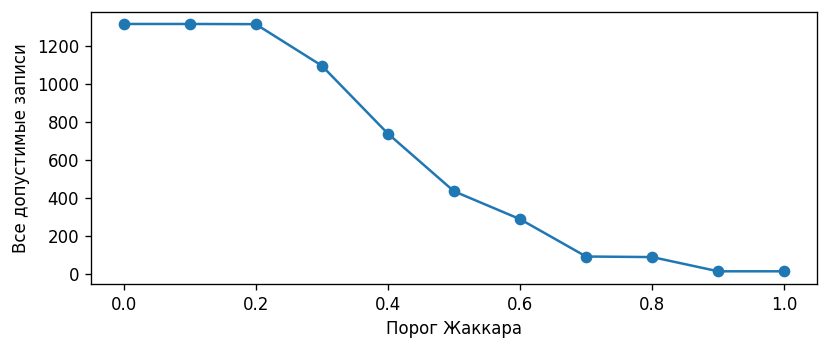

In [17]:
plt.figure(figsize=(7, 3))
plt.plot(thresholds, counts, marker="o")
plt.xlabel("Порог Жаккара")
plt.ylabel("Все допустимые записи")
plt.show()

Требование становится строже — допустимый набор сокращается или сохраняет размер. Между проверенными порогами число записей может изменяться скачками при пересечении оценок отдельных кандидатов. Мы получили полный алгоритм: описать объекты множествами, вычислить сходство, проверить логические условия и упорядочить выдачу. Его применимость к другим данным проверим на Zoo.

## 3. Самостоятельная работа: UCI Zoo

Найдите животных, похожих на **dolphin**, по наборам присутствующих бинарных свойств. Zoo — готовый учебный датасет из 101 записи. Ваша задача — перенести математическую модель и алгоритм поиска с жанров фильмов на свойства животных.

Сохраните последовательность: множество признаков → Жаккар → логический отбор → ранжирование → исследование порога. Изменится способ получения множества из исходной записи. Функцию сравнения и смысл её числителя со знаменателем можно сохранить.

В zoo.csv сохранены исходные записи и значения. Добавлен object_id по исходному порядку строк. Два имени frog относятся к разным записям: имя не всегда однозначно задаёт объект, поэтому запрос исключается по идентификатору.

### 3.0. Подготовленная загрузка Zoo

В MovieLens присутствующие признаки были перечислены внутри строки. В Zoo они уже записаны бинарными столбцами: 1 означает наличие свойства, 0 — отсутствие. Чтобы использовать ту же формулу, нужно из каждого животного получить множество названий свойств со значением 1.

Список 15 бинарных признаков указан явно. legs — количество конечностей, type — код класса: их значения имеют другой смысл и не входят в выбранное множество присутствующих свойств.

In [18]:
zoo_table = pd.read_csv("zoo.csv")
display(zoo_table.head())
zoo = zoo_table.to_dict("records")
feature_cols = [
    "hair", "feathers", "eggs", "milk", "airborne",
    "aquatic", "predator", "toothed", "backbone", "breathes",
    "venomous", "fins", "tail", "domestic", "catsize"
]
print("Число записей:", len(zoo))
print("Бинарные свойства:", feature_cols)

,object_id,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
0,1,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,2,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,3,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,4,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,5,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


Число записей: 101
Бинарные свойства: ['hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 'predator', 'toothed', 'backbone', 'breathes', 'venomous', 'fins', 'tail', 'domestic', 'catsize']


Готовые строки Zoo станут другим входом той же математической модели. Совместное отсутствие свойства не увеличивает Жаккар: мы сравниваем наборы присутствующих свойств. Исключение legs и type определяет границу вывода — найденная близость относится к выбранным бинарным признакам.

### S1. Множества присутствующих свойств

Математическая цель — определить, что именно означает описание животного в нашей модели. Преобразуйте бинарную запись в множество присутствующих свойств; от этого выбора зависит смысл всех последующих оценок.

Для каждого животного создайте пустое множество properties. Вторым циклом переберите feature_cols и добавьте название свойства, если его значение равно 1. Сохраните множество в поле property_set. Найдите dolphin и сохраните его идентификатор zoo_query_id и множество Z_query. Выведите свойства и их число. Объясните исключение legs и type.

In [ ]:
# Ваше решение S1
# Напишите код по образцу MovieLens.

### S2. Расчёт и независимая проверка

Математическая цель — проверить, что правило сходства работает для нового типа объектов. Пересечение должно содержать общие присутствующие свойства, объединение — все различные присутствующие свойства пары. Отдельная проверка поможет объяснить одну оценку через исходные данные.

Циклом сравните Z_query с каждым property_set через compare_sets. Создайте список zoo_result: идентификатор, название, common, union, jaccard. Отдельно найдите seal и проверьте сходство по исходным множествам. Выведите общие и различающиеся свойства.

In [ ]:
# Ваше решение S2
# Напишите код по образцу MovieLens.

### S3. Отбор и ранжирование

Математическая цель — соединить оценку сходства с логическим условием поиска. Различайте всех допустимых животных и десять записей, которые показывает выдача. Условие допуска и порядок результатов решают разные части задачи.

По образцу MovieLens запишите три вложенные проверки: животное отличается от запроса по идентификатору, Жаккар не меньше 0,5, общих свойств минимум три. Подходящие записи добавьте в отдельный список и выведите его длину.

По образцу `movie_score` напишите `zoo_score`, возвращающую коэффициент Жаккара. Отсортируйте подходящие записи по убыванию через `reverse=True` и покажите первые десять. При равных оценках сохраните исходный порядок. Объясните, как вложенные `if` реализуют логическое «И».

In [ ]:
# Ваше решение S3
# Напишите код по образцу MovieLens.

### S4. Порог и математическое объяснение

Математическая цель — связать наблюдение на данных с доказательством из лекции. При повышении только порога допустимые множества должны быть вложены. График показывает следствие для этого датасета; объяснение должно установить, почему оно выполняется.

Для порогов 0, 0,25, 0,5, 0,75 и 1 посчитайте все допустимые записи при минимуме трёх общих свойств. Используйте два цикла и счётчик, как в MovieLens. Постройте график. Обоснуйте невозрастание количества кандидатов через вложенность множеств. Назовите ограничение выбранного описания.

In [ ]:
# Ваше решение S4
# Напишите код по образцу MovieLens.

## 4. Обсуждение



Вернитесь к задаче лекции: содержательный вопрос «какие объекты похожи?» был преобразован в описание признаков, формулу, условия допуска и порядок выдачи. Оцените, какую часть смысла слова «похожий» сохранила эта модель.

1. Почему два фильма с тремя общими жанрами получают разные коэффициенты Жаккара? Объясните через знаменатель.
2. Почему сходство 1 не доказывает тождество фильмов или животных? Разделите объект и его описание.
3. Почему при повышении только порога количество кандидатов не возрастает? Свяжите условие J ≥ t с вложенностью допустимых множеств.
4. Что изменилось при переносе MovieLens на Zoo? Какие математические операции и части алгоритма сохранились?

Сформулируйте итоговый вывод: **по каким признакам сравниваются объекты, как измеряется сходство, какие объекты допускаются и чего результат не позволяет установить**. Полные решения самостоятельной части находятся в отдельном тексте объяснений.